In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_json('script-bag-of-words.json')

In [5]:
df.head()

,episodeAlt,seasonNum,episodeNum,episodeTitle,text
0,S1E1,1,1,Winter Is Coming,"[{'text': 'Easy, boy.', 'name': 'Will'}, {'tex..."
1,S1E2,1,2,The Kingsroad,"[{'text': 'And You child... drink, eat. need t..."
2,S1E3,1,3,Lord Snow,[{'text': 'Council. Grand Lord Maester Pycelle...
3,S1E4,1,4,"Cripples, Bastards, and Broken Things",[{'text': 'Lord's The again. been dreaming lit...
4,S1E5,1,5,The Wolf and the Lion,[{'text': 'Does Hugh Ser any capital? family h...


In [6]:
df.tail()

,episodeAlt,seasonNum,episodeNum,episodeTitle,text
68,S8E2,8,2,A Knight of the Seven Kingdoms,"[{'name': 'Daenerys Targaryen', 'text': 'About..."
69,S8E3,8,3,The Long Night,"[{'name': 'Northman #1', 'text': 'Oi!'}, {'nam..."
70,S8E4,8,4,The Last of the Starks,"[{'name': 'Jon Snow', 'text': 'And Everyone It..."
71,S8E5,8,5,The Bells,"[{'name': 'Lord Varys', 'text': 'And? Come Not..."
72,S8E6,8,6,The Iron Throne,"[{'name': 'Tyrion Lannister', 'text': 'I'll fi..."


In [7]:
df.iloc[-1]['text']

[{'name': 'Tyrion Lannister', 'text': "I'll find later. you"},
 {'name': 'Jon Snow', 'text': "It's Let me men not safe. send some with you."},
 {'name': 'Tyrion Lannister', 'text': "I'm alone. going"},
 {'name': 'Grey Worm',
  'text': 'Daenerys I In Queen, Targaryen, die. name of one sentence the the to true you'},
 {'name': 'Jon Snow',
  'text': "Grey It's These Worm! are men over. prisoners."},
 {'name': 'Grey Worm',
  'text': "It Queen's are defeated. enemies is not over the until"},
 {'name': 'Davos Seaworth',
  'text': "How They're be? defeated do knees. more much on their them to want you"},
 {'name': 'Grey Worm', 'text': 'They are breathing.'},
 {'name': 'Davos Seaworth', 'text': 'Look We around friend. won. you,'},
 {'name': 'Grey Worm', 'text': "I commands, my not obey queen's yours."},
 {'name': 'Jon Snow', 'text': "And Queen's are commands? the what"},
 {'name': 'Grey Worm',
  'text': '"Kill Cersei Lannister." These They all are chose fight follow for free her. men. to who'}

In [8]:
dialouge = {}
for index, row in df.iterrows():
    for item in row['text']:
        if item['name'] in dialouge:
            # append
            dialouge[item['name']] = dialouge[item['name']] + item['text']
        else:
            # create character
            dialouge[item['name']] = item['text'] + " "
        

In [9]:
len(dialouge)

817

In [10]:
new_df = pd.DataFrame()
new_df['character'] = dialouge.keys()
new_df['words'] = dialouge.values()

In [13]:
new_df.iloc[:,0:3].head()

,character,words
0,Will,"Easy, boy. I've I've Wildlings a a do ever in ..."
1,Waymar Royce,One They're What a and another before d'you ea...
2,Gared,Wall. We back head should the to Our They We W...
3,Jon Snow,Father's Go on. watching. And mother. yourBran...
4,Septa Mordane,"Fine Well always. as done. work, I Quite beaut..."


In [14]:
new_df['num_words'] = new_df['words'].apply(lambda x:len(x.split()))

In [15]:
new_df = new_df.sort_values('num_words',ascending=False)

In [16]:
new_df = new_df.head(100)

In [17]:
new_df.shape

(100, 3)

In [18]:
new_df.head()

,character,words,num_words
17,Tyrion Lannister,It Mmh. Northern about girls. is say the they ...,25924
13,Cersei Lannister,And And Casterly One Rock. When about afraid. ...,14294
3,Jon Snow,Father's Go on. watching. And mother. yourBran...,11488
20,Daenerys Targaryen,We've a and anything. asked been for for guest...,11202
12,Jaime Lannister,"As I It's brother, duty feel it's much. my sho...",10823


In [19]:
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer(stop_words='english')

In [20]:
embeddings = cv.fit_transform(new_df['words']).toarray()

In [21]:
embeddings.shape

(100, 15335)

In [22]:
embeddings = embeddings.astype('float64')

In [23]:
from sklearn.manifold import TSNE

In [44]:
tsne = TSNE(n_components=3, verbose=2, random_state=123)
z = tsne.fit_transform(embeddings)

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 100 samples in 0.003s...
[t-SNE] Computed neighbors for 100 samples in 0.048s...
[t-SNE] Computed conditional probabilities for sample 100 / 100
[t-SNE] Mean sigma: 14.377887
[t-SNE] Computed conditional probabilities in 0.004s
[t-SNE] Iteration 50: error = 86.5775452, gradient norm = 0.2873938 (50 iterations in 0.024s)
[t-SNE] Iteration 100: error = 99.9253845, gradient norm = 0.1656265 (50 iterations in 0.028s)
[t-SNE] Iteration 150: error = 103.6784363, gradient norm = 0.6637014 (50 iterations in 0.033s)
[t-SNE] Iteration 200: error = 110.3649292, gradient norm = 0.1391581 (50 iterations in 0.024s)
[t-SNE] Iteration 250: error = 110.1627045, gradient norm = 0.0998405 (50 iterations in 0.021s)
[t-SNE] KL divergence after 250 iterations with early exaggeration: 110.162704
[t-SNE] Iteration 300: error = 2.6444747, gradient norm = 0.0089758 (50 iterations in 0.020s)
[t-SNE] Iteration 350: error = 2.1557207, gradient norm = 0.0071

In [45]:
z.shape

(100, 3)

In [46]:
new_df['x'] = z.T[0]
new_df['y'] = z.T[1]

In [47]:
new_df

,character,words,num_words,x,y
17,Tyrion Lannister,It Mmh. Northern about girls. is say the they ...,25924,76.484497,-118.859756
13,Cersei Lannister,And And Casterly One Rock. When about afraid. ...,14294,85.308441,-78.054443
3,Jon Snow,Father's Go on. watching. And mother. yourBran...,11488,90.316566,67.622597
20,Daenerys Targaryen,We've a and anything. asked been for for guest...,11202,-83.763626,-66.249222
12,Jaime Lannister,"As I It's brother, duty feel it's much. my sho...",10823,65.010887,78.316437
...,...,...,...,...,...
132,Rickard Karstark,Castle I'll King North! Red The They and can c...,466,-40.327629,-6.525733
57,Syrio Forel,"Tomorrow You are at be boy. here late, midday....",462,-23.865471,77.712219
112,Kevan Lannister,Tyrion. Catelyn Golden Jaime Lords River River...,460,-28.453335,28.583899
365,Mace Tyrell,"From Grace, House Margaery May Reach, Tyrell Y...",450,-65.700012,93.028870


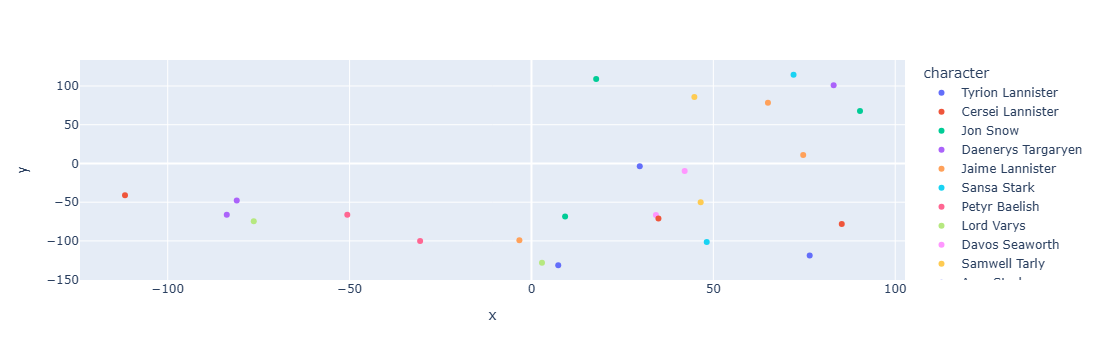

In [48]:
import plotly.express as px
fig = px.scatter(new_df.head(25), x="x", y="y", color="character")
fig.show()

In [49]:
new_df.to_csv('data.csv', index=False)